## RESTORATION CELL

In [2]:
import os
import shutil
from google.colab import drive

# checks if drive is already mounted
if not os.path.exists('/content/drive/MyDrive'):
  drive.mount('/content/drive')

!pip install -q ultralytics

# ensure project folders exist
drive_dir = '/content/drive/MyDrive/drone_project'
os.makedirs(f'{drive_dir}/configs', exist_ok=True)
os.makedirs(f'{drive_dir}/data_zips', exist_ok=True)
os.makedirs(f'{drive_dir}/runs/drone_yolo11m_960/weights', exist_ok=True)
os.makedirs(f'{drive_dir}/submissions', exist_ok=True)

# checks if best.pt is missing from drive, if missing then it copies
# into drive so nothing is lost
drive_best = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
if not os.path.exists(drive_best):
  if os.path.exists('/content/drone_project/runs/drone_yolo11m_960/weights/best.pt'):
    shutil.copy2('/content/drone_project/runs/drone_yolo11m_960/weights/best.pt', drive_best)
  elif os.path.exists(f'{drive_dir}/weights/best.pt'):
    shutil.copy2(f'{drive_dir}/weights/best.pt', drive_best)

# checks if drone_human.yaml is missing from drive, if missing then it copies
# into drive so nothing is lost
drive_yaml = f'{drive_dir}/configs/drone_human.yaml'
if not os.path.exists(drive_yaml) and os.path.exists('/content/drone_project/configs/drone_human.yaml'):
  shutil.copy2('/content/drone_project/configs/drone_human.yaml', drive_yaml)

# checks if drone_human.zip is missing from drive, if missing then it copies
# into drive so nothing is lost
drive_zip = f'{drive_dir}/data_zips/drone_human.zip'
if not os.path.exists(drive_zip) and os.path.exists('/content/datasets/drone_human/images/val'):
  shutil.make_archive(f'{drive_dir}/data_zips/drone_human', 'zip', '/content/datasets/drone_human')

# if the path doesn't exist but drone_human.zip exists
# it unzips the archive into the notebook
if not os.path.exists('/content/datasets/drone_human/images/val') and os.path.exists(drive_zip):
  os.makedirs('/content/datasets/drone_human', exist_ok=True)
  !unzip -q -o {drive_zip} -d /content/datasets/drone_human

print("drive restoration complete!")
print("val images ready:", len(os.listdir('/content/datasets/drone_human/images/val')))
print("best.pt in drive:", os.path.exists(drive_best))

drive restoration complete!
val images ready: 400
best.pt in drive: True


## Step 1: build the train and val dataset from Visdrone

VisDrone2019-DET-tr 100%[===================>]   1.44G   233MB/s    in 6.6s    
VisDrone2019-DET-va 100%[===================>]  77.86M   273MB/s    in 0.3s    
done building dataset and saved zip to google drive
drone train images: 2500 | drone val images: 400


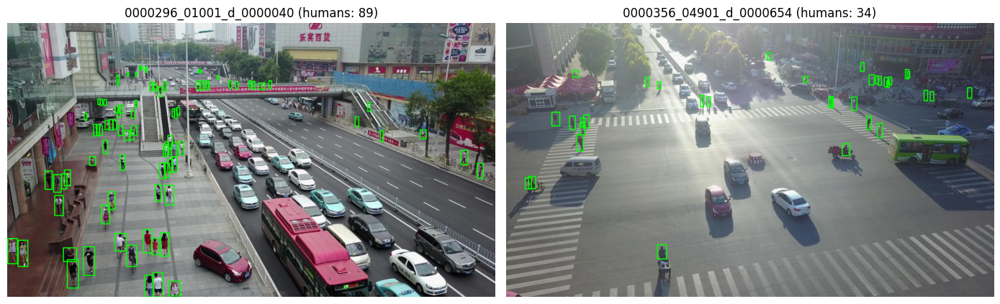

In [4]:
import os
import cv2
import shutil
import random
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
  drive.mount('/content/drive')

!pip install -q ultralytics

random.seed(42)

# creates the permanent drive folders
drive_dir = '/content/drive/MyDrive/drone_project'
os.makedirs('/content/raw_visdrone', exist_ok=True)
os.makedirs(f'{drive_dir}/configs', exist_ok=True)
os.makedirs(f'{drive_dir}/data_zips', exist_ok=True)
os.makedirs(f'{drive_dir}/runs', exist_ok=True)
os.makedirs(f'{drive_dir}/submissions', exist_ok=True)

# downloads the visdrone train and validation datasets and unzips
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -P /content/raw_visdrone
!wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -P /content/raw_visdrone

!unzip -q -o /content/raw_visdrone/VisDrone2019-DET-train.zip -d /content/raw_visdrone
!unzip -q -o /content/raw_visdrone/VisDrone2019-DET-val.zip -d /content/raw_visdrone

# deletes any old drone_human folder and recreates the proper
# folder layout for YOLO
base_out = '/content/datasets/drone_human'
if os.path.exists(base_out):
  shutil.rmtree(base_out)

for split in ['train', 'val']:
  os.makedirs(f'{base_out}/images/{split}', exist_ok=True)
  os.makedirs(f'{base_out}/labels/{split}', exist_ok=True)

def collect_visdrone(split_folder, max_imgs):
  # list all .txt files and shuffles them
  img_dir = f'/content/raw_visdrone/{split_folder}/images'
  ann_dir = f'/content/raw_visdrone/{split_folder}/annotations'
  items = []
  fnames = sorted(os.listdir(ann_dir))
  random.shuffle(fnames)
  for fname in fnames:
    # for each .txt file find the matching .jpg and read its
    # width and height
    if not fname.endswith('.txt'):
      continue
    base = fname[:-4]
    img_path = os.path.join(img_dir, base + '.jpg')
    if not os.path.exists(img_path):
      continue
    with Image.open(img_path) as im:
      W, H = im.size
    lines = []
    with open(os.path.join(ann_dir, fname), 'r') as f:
      # loop through every rown in visdrone .txt file
      for row in f:
        parts = row.strip().split(',')
        if len(parts) < 6:
          continue
        x, y, w, h, score, cat = map(float, parts[:6])
        # 1 and 2 are people classes, everything else is discarded
        if int(cat) in [1, 2] and w > 1 and h > 1:
          # coordinate conversion
          xc = max(0.0, min(1.0, (x + w / 2) / W))
          yc = max(0.0, min(1.0, (y + h / 2) / H))
          nw = max(0.0, min(1.0, w / W))
          nh = max(0.0, min(1.0, h / H))
          lines.append(f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")
    # keeps images with at least 1 human
    if len(lines) > 0:
      items.append((img_path, base, lines))
      # stops when max_imgs reached (2500 train, 400 val)
      if len(items) >= max_imgs:
          break
  return items

# copies each .jpg to image/{split}/ and writes the converted
# YOLO label lines to labels/{split}/{name}.txt
train_items = collect_visdrone('VisDrone2019-DET-train', 2500)
val_items = collect_visdrone('VisDrone2019-DET-val', 400)

for split, items in [('train', train_items), ('val', val_items)]:
  for src_img, name, lines in items:
    shutil.copy2(src_img, f"{base_out}/images/{split}/{name}.jpg")
    with open(f"{base_out}/labels/{split}/{name}.txt", 'w') as f:
      f.write('\n'.join(lines))

# writes drone_human.yaml into google drive
# it tells YOLO where the train and val images are
# how many classes and class name
yaml_path = f'{drive_dir}/configs/drone_human.yaml'
with open(yaml_path, 'w') as f:
  f.write(f"path: {base_out}\ntrain: images/train\nval: images/val\nnc: 1\nnames:\n  0: human\n")

shutil.make_archive(f'{drive_dir}/data_zips/drone_human', 'zip', base_out)

print("done building dataset and saved zip to google drive")
print("drone train images:", len(train_items), "| drone val images:", len(val_items))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (src_img, name, lines) in zip(axes, val_items[:2]):
  img = cv2.imread(f"{base_out}/images/val/{name}.jpg")
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  H, W, _ = img.shape
  for line in lines:
    _, xc, yc, nw, nh = map(float, line.split())
    x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
    x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
  ax.imshow(img)
  ax.set_title(f"{name} (humans: {len(lines)})")
  ax.axis('off')

plt.tight_layout()
plt.show()

## Step 2: train the yolo11m model

* i used 960px instead of 640 for higher resolution so tiny far people dont become blurry
* `hsv_s=0.7`, `hsv_v=0.5` and `scale=0.6` values are set so that the model can handle harsh sun, shadows and different drone altitudes

In [6]:
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'
save_dir = f'{drive_dir}/runs'

# downloads coco pretrained weights
model = YOLO('yolo11m.pt')
res = model.train(
  data=yaml_file, # points to drone_human.yaml
  epochs=20,
  patience=6, # stopping when val acc doesn't improve for 6 epochs
  imgsz=960, # resize images to 960x960
  batch=8,
  fliplr=0.5, # 50% chance to mirror images horizontally
  hsv_h=0.02, # random adjustments to hue, sat, brightness
  hsv_s=0.7,
  hsv_v=0.5,
  scale=0.6, # randomly zoom images in or out by 60%
  project=save_dir,
  name='drone_yolo11m_960', # saving weights to drive
  exist_ok=True
)

# reload best.pt
best_path = f'{save_dir}/drone_yolo11m_960/weights/best.pt'
best_model = YOLO(best_path)

# run once for conf=0.01 and conf=0.25
m_default = best_model.val(data=yaml_file, imgsz=960, conf=0.25, verbose=False)
m_opt = best_model.val(data=yaml_file, imgsz=960, conf=0.01, verbose=False)

print("finished pure drone training, saved directly to google drive")
print("drone val (960px, conf=0.25) mAP50:", round(m_default.box.map50, 4))
print("drone val (960px, conf=0.01) mAP50:", round(m_opt.box.map50, 4))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drone_project/configs/drone_human.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript

## Step 3:
* saving best.pt
* testing two modifications:
  * increase res to 1280px instead of 960px
  * test `augment=True`, pass zoomed and flipped frames through the gpu
* visualizing the predictions on 4 scenes

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2222.4±324.6 MB/s, size: 190.6 KB)
val: Scanning /content/datasets/drone_human/labels/val... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.3Kit/s 0.3s
val: New cache created: /content/datasets/drone_human/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.9it/s 13.2s
                   all        400      10897       0.74      0.593      0.658      0.306
Speed: 1.4ms preprocess, 25.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/detect/val-3
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅

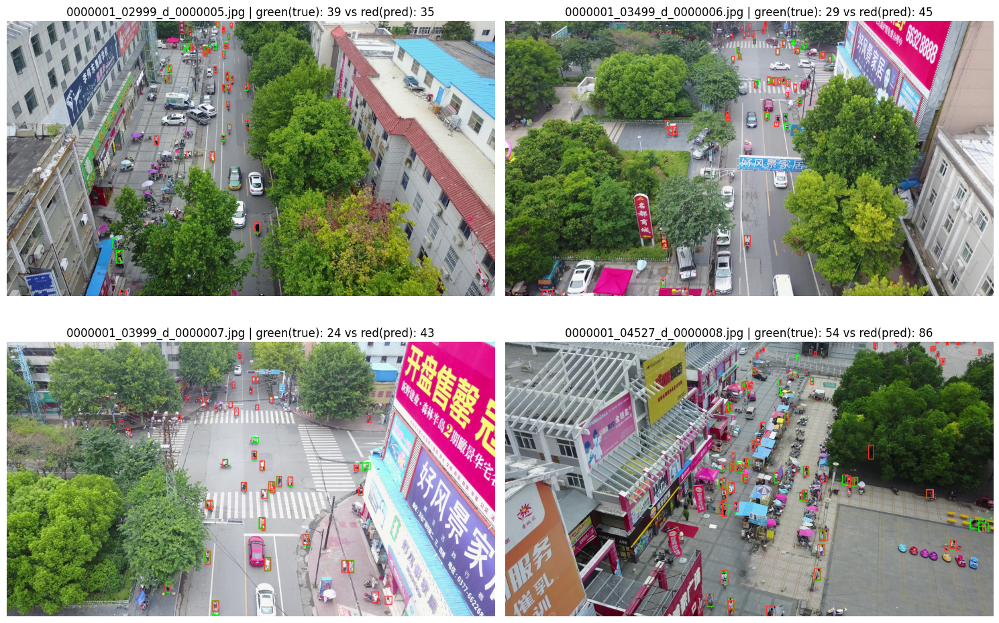

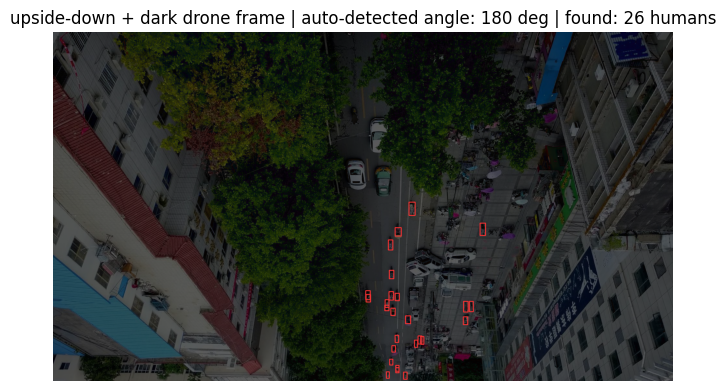

In [8]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# loads best.pt weights
drive_dir = '/content/drive/MyDrive/drone_project'
best_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'

model = YOLO(best_path)

# run validation at imgsz=1280
m_1280 = model.val(data=yaml_file, imgsz=1280, conf=0.01, verbose=False)
# run validation at augment=True
m_tta = model.val(data=yaml_file, imgsz=1280, conf=0.01, augment=True, verbose=False)

print("baseline drone val (960px, conf=0.01) mAP50: 0.6141")
print("upgrade 1 -> 1280px (conf=0.01) mAP50:", round(m_1280.box.map50, 4))
print("upgrade 2 -> 1280px + TTA (conf=0.01) mAP50:", round(m_tta.box.map50, 4))

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
samples = sorted(os.listdir(val_img_dir))[:4]

# visual comparison on 4 val scenes
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, fname in zip(axes.flatten(), samples):
  img_path = os.path.join(val_img_dir, fname)
  lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  H, W, _ = img.shape

  gt_count = 0
  with open(lbl_path, 'r') as f:
    for line in f:
      parts = line.strip().split()
      if not parts:
        continue
      gt_count += 1
      _, xc, yc, nw, nh = map(float, parts)
      x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
      x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
      cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

  res = model.predict(img_path, imgsz=1280, conf=0.20, augment=True, verbose=False)[0]
  pred_count = len(res.boxes)
  for box in res.boxes:
    px1, py1, px2, py2 = map(int, box.xyxy[0].tolist())
    cv2.rectangle(img, (px1, py1), (px2, py2), (255, 50, 50), 2)

  ax.imshow(img)
  ax.set_title(f"{fname} | green(true): {gt_count} vs red(pred): {pred_count}")
  ax.axis('off')

plt.tight_layout()
plt.show()

# convert image from BGR to LAB (lightness/brightness, A and B is color tint)
def apply_clahe(img):
  lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
  l, a, b = cv2.split(lab)
  # applying clahe to the L only
  # boosting local contrast in dark shadows without making noise
  clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
  l = clahe.apply(l)
  return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def predict_smart_drone(model, img, imgsz=1280, conf_min=0.01):
  # if avg pixel brightness < 80, enhance the image with apply clahe
  work_img = apply_clahe(img) if img.mean() < 80 else img
  # create 0, 90 CW, 180 and 270 CCW copies and feeds
  # all 4 images in a single model.predict call
  img90 = cv2.rotate(work_img, cv2.ROTATE_90_CLOCKWISE)
  img180 = cv2.rotate(work_img, cv2.ROTATE_180)
  img270 = cv2.rotate(work_img, cv2.ROTATE_90_COUNTERCLOCKWISE)

  preds = model.predict([work_img, img90, img180, img270], imgsz=imgsz, conf=conf_min, verbose=False)
  rots = [0, 90, 180, 270]

  """ for each rotated pred, conf = 0.25, sums the top 8, and adds
  0.15 bonus to 0 degrees (no rotation) so an already normal image
  isnt overridden by noise """
  best_idx = 0
  best_score = -1.0
  for idx, r in enumerate(preds):
    confs = r.boxes.conf.cpu().numpy() if len(r.boxes) > 0 else np.array([])
    high_confs = confs[confs >= 0.25]
    score = float(np.sum(np.sort(high_confs)[-8:])) if len(high_confs) > 0 else 0.0
    # adds 0.15 bonus to the 0 degree image
    if idx == 0:
      score += 0.15
    if score > best_score:
      best_score = score
      best_idx = idx

  # when winning angle is chosen, boxes in a rotated frame
  # are rotated back to original image coordinates
  chosen = preds[best_idx]
  rot = rots[best_idx]
  out_boxes = []
  for box in chosen.boxes:
    c = float(box.conf[0].item())
    xc, yc, nw, nh = box.xywhn[0].tolist()
    if rot == 90:
      xc, yc, nw, nh = yc, 1.0 - xc, nh, nw
    elif rot == 180:
      xc, yc, nw, nh = 1.0 - xc, 1.0 - yc, nw, nh
    elif rot == 270:
      xc, yc, nw, nh = 1.0 - yc, xc, nh, nw
    out_boxes.append((c, xc, yc, nw, nh))
  return out_boxes, rot

sample_drone = cv2.imread(os.path.join(val_img_dir, samples[0]))
rot_drone = cv2.rotate(sample_drone, cv2.ROTATE_180)
dark_rot_drone = cv2.convertScaleAbs(rot_drone, alpha=0.45, beta=-20)

boxes_rot, detected_rot = predict_smart_drone(model, dark_rot_drone, imgsz=1280, conf_min=0.20)
vis_rot = cv2.cvtColor(dark_rot_drone.copy(), cv2.COLOR_BGR2RGB)
H, W, _ = vis_rot.shape
for c, xc, yc, nw, nh in boxes_rot:
  x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
  x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
  cv2.rectangle(vis_rot, (x1, y1), (x2, y2), (255, 50, 50), 2)

plt.figure(figsize=(8, 5))
plt.imshow(vis_rot)
plt.title(f"upside-down + dark drone frame | auto-detected angle: {detected_rot} deg | found: {len(boxes_rot)} humans")
plt.axis('off')
plt.show()

We wont use `augment=True` anymore because it hurts accuracy because it runs 3 passes on the image with different zooms, one of the passes zooms out the image making the people blurred

We'll keep the resolution at 1280px because the map50 has risen

## Step 4:

* We'll test iou = 0.45, 0.5, 0.55, 0.6 at 1280px without augment=True and and testing with the 4 images

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2540.9±694.9 MB/s, size: 203.4 KB)
val: Scanning /content/datasets/drone_human/labels/val... 400 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 400/400 1.1Kit/s 0.4s
val: New cache created: /content/datasets/drone_human/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.0it/s 12.7s
                   all        400      10897      0.745      0.615      0.663        0.3
Speed: 1.5ms preprocess, 24.6

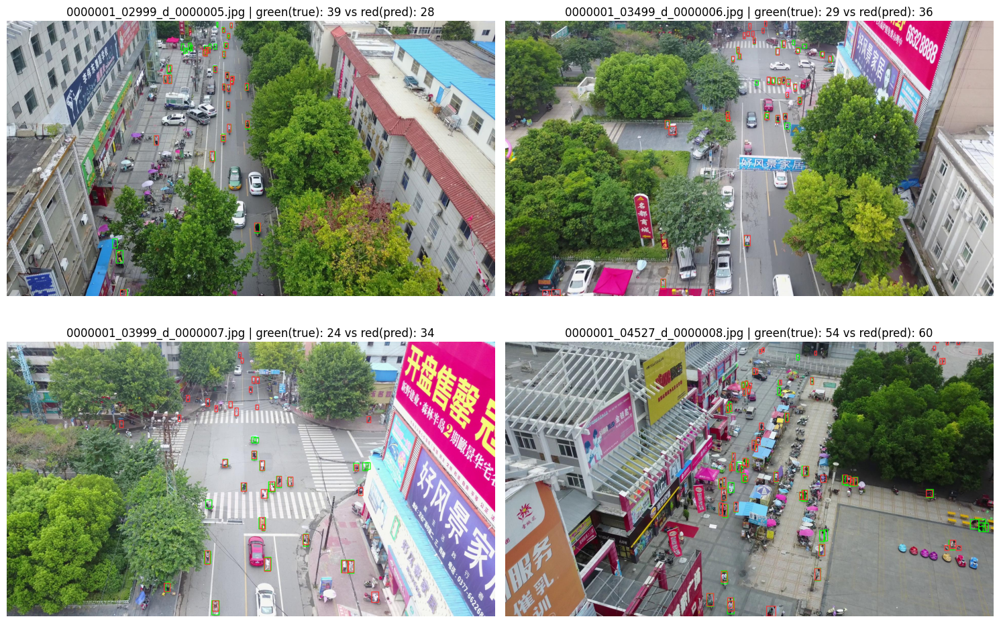

In [11]:
import os
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
best_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'

model = YOLO(best_path)

# start from the prev best
best_iou = 0.70
best_map = 0.6582

# loop iou_val over test values
for iou_val in [0.45, 0.50, 0.55, 0.60]:
  # run model.val() at each value and saves highest map@0.50
  m = model.val(data=yaml_file, imgsz=1280, conf=0.01, iou=iou_val, verbose=False)
  score = round(m.box.map50, 4)
  print(f"1280px (conf=0.01, iou={iou_val}) mAP50:", score)
  if score > best_map:
    best_map = score
    best_iou = iou_val

print("best iou setting:", best_iou, "with mAP50:", best_map)

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
samples = sorted(os.listdir(val_img_dir))[:4]

# replot same 4 val scenes using iou=best_iou and conf=0.25
# without augment=True
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, fname in zip(axes.flatten(), samples):
  img_path = os.path.join(val_img_dir, fname)
  lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))
  img = cv2.imread(img_path)
  img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  H, W, _ = img.shape

  gt_count = 0
  with open(lbl_path, 'r') as f:
    for line in f:
      parts = line.strip().split()
      if not parts:
        continue
      gt_count += 1
      _, xc, yc, nw, nh = map(float, parts)
      x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
      x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
      cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

  res = model.predict(img_path, imgsz=1280, conf=0.25, iou=best_iou, verbose=False)[0]
  pred_count = len(res.boxes)
  for box in res.boxes:
    px1, py1, px2, py2 = map(int, box.xyxy[0].tolist())
    cv2.rectangle(img, (px1, py1), (px2, py2), (255, 50, 50), 2)

  ax.imshow(img)
  ax.set_title(f"{fname} | green(true): {gt_count} vs red(pred): {pred_count}")
  ax.axis('off')

plt.tight_layout()
plt.show()

First plot had worse performance but the other plots did significantly better because iou=0.55 removed the double red boxes on the same person

## Step 5:
* We will now train a second model `YOLOv9c` on the same training data at 960px then test after on the same settings of `1280px`, `conf=0.01` and `iou=0.55`

* YOLOv9c uses PGI (programmable gradient information) that perserve final spatial details across deep layers, making it very strong on tiny, low contrast aerial humans

In [14]:
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
yaml_file = f'{drive_dir}/configs/drone_human.yaml'
save_dir = f'{drive_dir}/runs'

# load pretrained yolov9c.pt and trains with same hyperparameters
# in Cell 5
v9_model = YOLO('yolov9c.pt')
res = v9_model.train(
  data=yaml_file,
  epochs=20,
  patience=6,
  imgsz=960,
  batch=8,
  fliplr=0.5,
  hsv_h=0.02,
  hsv_s=0.7,
  hsv_v=0.5,
  scale=0.6,
  project=save_dir,
  name='drone_yolov9c_960',
  exist_ok=True
)

v9_best_path = f'{save_dir}/drone_yolov9c_960/weights/best.pt'
v9_best = YOLO(v9_best_path)

m_v9 = v9_best.val(data=yaml_file, imgsz=1280, conf=0.01, iou=0.55, verbose=False)

print("finished yolov9c drone training, saved to google drive")
print("yolo11m (1280px, conf=0.01, iou=0.55) mAP50: 0.6672")
print("yolov9c (1280px, conf=0.01, iou=0.55) mAP50:", round(m_v9.box.map50, 4))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/drone_project/configs/drone_human.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.7, hsv_v=0.5, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9c.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=drone_yolov9c_960, nbs=64, nm

As expected, YOLOv9c performed better without any tweaks because it has "strong feature retention for small/low contrast people"

## Step 6:
* installing ensemble-boxes library and combining the predictions of both models using WBF and testing if their combined predictions beats yolov9c alone

* WBF: instead of deleting overlapping boxes from different models, it blends or averages their coordinates (weighted by each box's confidence and model weight) to make a more accurate box

In [17]:
import os
import numpy as np
from ultralytics import YOLO

!pip install -q ensemble-boxes
from ensemble_boxes import weighted_boxes_fusion

# load both pretrained models
drive_dir = '/content/drive/MyDrive/drone_project'
v11_path = f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt'
v9_path = f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt'

v11_model = YOLO(v11_path)
v9_model = YOLO(v9_path)

val_img_dir = '/content/datasets/drone_human/images/val'
val_lbl_dir = '/content/datasets/drone_human/labels/val'
fnames = sorted(os.listdir(val_img_dir))

gt_by_img = {}
total_gt = 0
preds_v11 = []
preds_v9 = []
preds_wbf = []

for idx, fname in enumerate(fnames):
  img_path = os.path.join(val_img_dir, fname)
  # read each image's .txt label file
  lbl_path = os.path.join(val_lbl_dir, fname.replace('.jpg', '.txt'))

  gts = []
  with open(lbl_path, 'r') as f:
    for line in f:
      parts = line.strip().split()
      if not parts:
        continue
      # converts xc, yc, nw, nh to normalized corners
      _, xc, yc, nw, nh = map(float, parts)
      gts.append([xc - nw / 2, yc - nh / 2, xc + nw / 2, yc + nh / 2])
  gt_by_img[idx] = np.array(gts, dtype=np.float32) if gts else np.zeros((0, 4), dtype=np.float32)
  total_gt += len(gts)

  # run both models
  r9 = v9_model.predict(img_path, imgsz=1280, conf=0.01, iou=0.55, verbose=False)[0]
  r11 = v11_model.predict(img_path, imgsz=1280, conf=0.01, iou=0.55, verbose=False)[0]

  # save standalone preds
  b9 = np.clip(r9.boxes.xyxyn.cpu().numpy(), 0.0, 1.0).tolist() if len(r9.boxes) > 0 else []
  s9 = r9.boxes.conf.cpu().numpy().tolist() if len(r9.boxes) > 0 else []
  l9 = [0] * len(s9)

  b11 = np.clip(r11.boxes.xyxyn.cpu().numpy(), 0.0, 1.0).tolist() if len(r11.boxes) > 0 else []
  s11 = r11.boxes.conf.cpu().numpy().tolist() if len(r11.boxes) > 0 else []
  l11 = [0] * len(s11)

  for c, box in zip(s11, b11):
    preds_v11.append((c, idx, box))
  for c, box in zip(s9, b9):
    preds_v9.append((c, idx, box))

  # run WBF
  if b9 or b11:
    w_boxes, w_scores, _ = weighted_boxes_fusion(
      [b9, b11],
      [s9, s11],
      [l9, l11],
      weights=[1.3, 1.0],
      iou_thr=0.55,
      skip_box_thr=0.01
    )
    for c, box in zip(w_scores, w_boxes):
      preds_wbf.append((float(c), idx, box.tolist()))

# created because ultralytics val function scores a single
# YOLO model, not a fused WBF ensemble
def eval_preds(all_preds):
  # sort the predicted boxes across the 400 images
  # from highest conf to lowest
  all_preds.sort(key=lambda x: x[0], reverse=True)
  tp = np.zeros(len(all_preds))
  fp = np.zeros(len(all_preds))
  matched = {i: np.zeros(len(gt_by_img[i]), dtype=bool) for i in gt_by_img}

  for i, (conf, img_idx, pbox) in enumerate(all_preds):
    gts = gt_by_img[img_idx]
    if len(gts) == 0:
      fp[i] = 1
      continue
    ix1 = np.maximum(gts[:, 0], pbox[0])
    iy1 = np.maximum(gts[:, 1], pbox[1])
    ix2 = np.minimum(gts[:, 2], pbox[2])
    iy2 = np.minimum(gts[:, 3], pbox[3])
    inter = np.maximum(0.0, ix2 - ix1) * np.maximum(0.0, iy2 - iy1)
    area_p = (pbox[2] - pbox[0]) * (pbox[3] - pbox[1])
    area_g = (gts[:, 2] - gts[:, 0]) * (gts[:, 3] - gts[:, 1])
    ious = inter / (area_p + area_g - inter + 1e-6)
    best_j = int(np.argmax(ious))
    if ious[best_j] >= 0.50 and not matched[img_idx][best_j]:
      tp[i] = 1
      matched[img_idx][best_j] = True
    else:
      fp[i] = 1

  cum_tp = np.cumsum(tp)
  cum_fp = np.cumsum(fp)
  rec = cum_tp / total_gt
  prec = cum_tp / (cum_tp + cum_fp + 1e-6)

  mrec = np.concatenate(([0.0], rec, [1.0]))
  mpre = np.concatenate(([1.0], prec, [0.0]))
  for i in range(len(mpre) - 1, 0, -1):
    mpre[i - 1] = max(mpre[i - 1], mpre[i])
  x = np.linspace(0, 1, 101)
  return float(np.trapezoid(np.interp(x, mrec, mpre), x))

map_11 = eval_preds(preds_v11)
map_9 = eval_preds(preds_v9)
map_wbf = eval_preds(preds_wbf)

print("custom eval yolo11m alone mAP50:", round(map_11, 4))
print("custom eval yolov9c alone mAP50:", round(map_9, 4))
print("wbf ensemble (yolov9c + yolo11m) mAP50:", round(map_wbf, 4))

custom eval yolo11m alone mAP50: 0.6815
custom eval yolov9c alone mAP50: 0.6956
wbf ensemble (yolov9c + yolo11m) mAP50: 0.7058


## Importing the test dataset

In [19]:
import os
import shutil
import pandas as pd
import kagglehub

kagglehub.login()

path = kagglehub.competition_download('human-detection-ae')
print("path to competition files:", path)

drive_dir = '/content/drive/MyDrive/drone_project'
test_dest = f'{drive_dir}/test_images'
sample_dest = f'{drive_dir}/sample_submission.csv'

for root, dirs, f_list in os.walk(path):
  for f in f_list:
    if f.lower().endswith('.csv'):
      src_csv = os.path.join(root, f)
      shutil.copy2(src_csv, sample_dest)
      print("copied sample submission to drive:", f)
      df_sample = pd.read_csv(sample_dest)
      print("sample submission rows:", len(df_sample), "| columns:", list(df_sample.columns))
      print(df_sample.head(3))

  imgs = [f for f in f_list if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
  if len(imgs) >= 50:
    print("found competition images in:", root, "| total count:", len(imgs))
    if os.path.exists(test_dest):
      shutil.rmtree(test_dest)
    os.makedirs(test_dest, exist_ok=True)
    for img_name in imgs:
      shutil.copy2(os.path.join(root, img_name), os.path.join(test_dest, img_name))

print("copied test images to google drive:", len(os.listdir(test_dest)))

100%|██████████| 399M/399M [00:24<00:00, 17.4MB/s]

Extracting files...


path to competition files: /root/.cache/kagglehub/competitions/human-detection-ae
copied sample submission to drive: sample_submission.csv
sample submission rows: 590 | columns: ['image_id', 'PredictionString']
     image_id                            PredictionString
0  test_00001  0 0.95 0.500000 0.500000 0.200000 0.400000
1  test_00002                                         NaN
2  test_00003                                         NaN
found competition images in: /root/.cache/kagglehub/competitions/human-detection-ae/test_images/test_images | total count: 605
copied test images to google drive: 605
Kaggle credentials set.
Kaggle credentials successfully validated.


# Step 7: Final inference and submission

In [21]:
!pip install -q ensemble-boxes

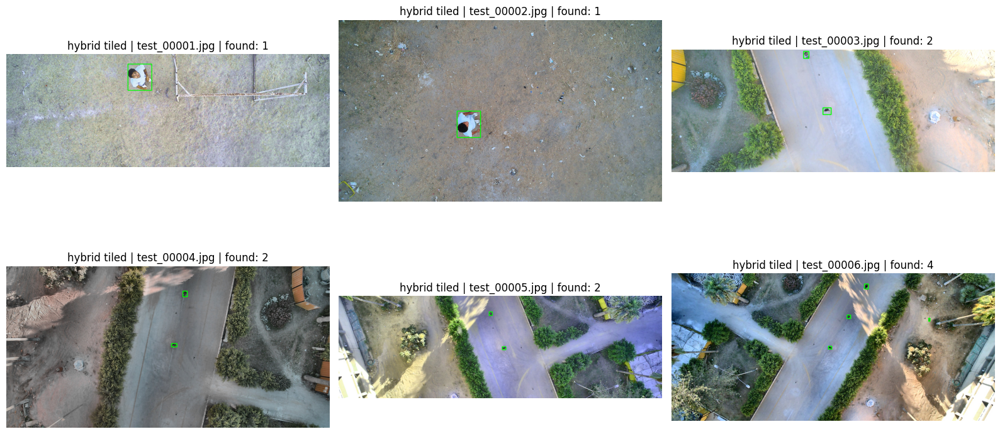

saved updated submission to: /content/drive/MyDrive/drone_project/submissions/submission.csv
total rows: 590 | empty background rows: 24
  test_00001 -> 0 0.8943 0.412739 0.205464 0.073533 0.232200
  test_00002 -> 0 0.9224 0.402836 0.574255 0.072387 0.145523
  test_00003 -> 0 0.6666 0.416448 0.043577 0.016358 0.056700 0 0.6654 0.480864 0.503240 0.025427 0.054520
  test_00004 -> 0 0.5879 0.519128 0.490668 0.017058 0.019819 0 0.5430 0.552791 0.174574 0.013737 0.033681
  test_00005 -> 0 0.6283 0.470458 0.174663 0.010144 0.035831 0 0.5917 0.511604 0.511561 0.011803 0.029484


In [22]:
import os
import cv2
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
sub_out = f'{drive_dir}/submissions/submission.csv'

v9_path = f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt'
v9_model = YOLO(v9_path)
coco_model = YOLO('yolo11l.pt')

def detect_nosedown_hybrid(img):
  H, W, _ = img.shape
  all_boxes = []
  all_scores = []

  img_180 = cv2.rotate(img, cv2.ROTATE_180)
  full_preds = coco_model.predict([img, img_180], imgsz=1280, classes=[0], conf=0.16, iou=0.45, verbose=False)

  for box in full_preds[0].boxes:
    c = float(box.conf[0].item())
    x1, y1, x2, y2 = box.xyxyn[0].tolist()
    all_boxes.append([x1, y1, x2, y2])
    all_scores.append(c)

  for box in full_preds[1].boxes:
    c = float(box.conf[0].item())
    if c >= 0.22:
      fx1, fy1, fx2, fy2 = box.xyxyn[0].tolist()
      all_boxes.append([1.0 - fx2, 1.0 - fy2, 1.0 - fx1, 1.0 - fy1])
      all_scores.append(c * 0.95)

  windows = [
    (0, int(W * 0.48)),
    (int(W * 0.26), int(W * 0.74)),
    (int(W * 0.52), W)
  ]
  tiles = [img[:, xs:xe] for xs, xe in windows]
  tile_preds = coco_model.predict(tiles, imgsz=960, classes=[0], conf=0.20, iou=0.45, verbose=False)

  for (xs, xe), r_tile in zip(windows, tile_preds):
    tw = xe - xs
    for box in r_tile.boxes:
      c = float(box.conf[0].item())
      tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
      if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
          continue
      nx1 = max(0.0, min(1.0, (tx1 + xs) / W))
      ny1 = max(0.0, min(1.0, ty1 / H))
      nx2 = max(0.0, min(1.0, (tx2 + xs) / W))
      ny2 = max(0.0, min(1.0, ty2 / H))
      all_boxes.append([nx1, ny1, nx2, ny2])
      all_scores.append(c)

  r_v9 = v9_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
  for box in r_v9.boxes:
    c = float(box.conf[0].item())
    x1, y1, x2, y2 = box.xyxyn[0].tolist()
    all_boxes.append([x1, y1, x2, y2])
    all_scores.append(c * 0.90)

  if not all_boxes:
    return []

  b_tensor = torch.tensor(all_boxes, dtype=torch.float32)
  s_tensor = torch.tensor(all_scores, dtype=torch.float32)
  keep = torchvision.ops.nms(b_tensor, s_tensor, iou_threshold=0.45).tolist()

  final_dets = []
  for idx in keep:
    x1, y1, x2, y2 = all_boxes[idx]
    c = all_scores[idx]
    xc = max(0.0, min(1.0, (x1 + x2) / 2.0))
    yc = max(0.0, min(1.0, (y1 + y2) / 2.0))
    nw = max(0.0, min(1.0, x2 - x1))
    nh = max(0.0, min(1.0, y2 - y1))
    if nw > 0.002 and nh > 0.002:
      final_dets.append((c, xc, yc, nw, nh))

  final_dets.sort(key=lambda x: x[0], reverse=True)
  return final_dets

first_six = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, fname in zip(axes.flatten(), first_six):
  img = cv2.imread(os.path.join(test_dir, fname))
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  H, W, _ = img.shape
  dets = detect_nosedown_hybrid(img)
  for c, xc, yc, nw, nh in dets:
    x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
    x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
  ax.imshow(img_rgb)
  ax.set_title(f"hybrid tiled | {fname} | found: {len(dets)}")
  ax.axis('off')
plt.tight_layout()
plt.show()

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

fnames = sorted([f for f in os.listdir(test_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
file_map = {}
for f in fnames:
  file_map[f] = f
  file_map[os.path.splitext(f)[0]] = f

rows = []
empty_count = 0
for img_id in target_ids:
  fname = file_map.get(img_id, file_map.get(os.path.splitext(img_id)[0], None))
  if fname is None:
    rows.append({'image_id': img_id, 'PredictionString': ""})
    empty_count += 1
    continue
  img = cv2.imread(os.path.join(test_dir, fname))
  dets = detect_nosedown_hybrid(img) if img is not None else []
  if not dets:
    empty_count += 1
    rows.append({'image_id': img_id, 'PredictionString': ""})
  else:
    parts = [f"0 {c:.4f} {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}" for c, xc, yc, nw, nh in dets]
    rows.append({'image_id': img_id, 'PredictionString': " ".join(parts)})

sub_df = pd.DataFrame(rows)
sub_df.to_csv(sub_out, index=False)

print("saved updated submission to:", sub_out)
print("total rows:", len(sub_df), "| empty background rows:", empty_count)
for i in range(5):
  print(" ", sub_df.iloc[i]['image_id'], "->", sub_df.iloc[i]['PredictionString'][:90])

## Step 8: Multi-Model

YOLO11x + YOLO11l + YOLOv9c + YOLO11m

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


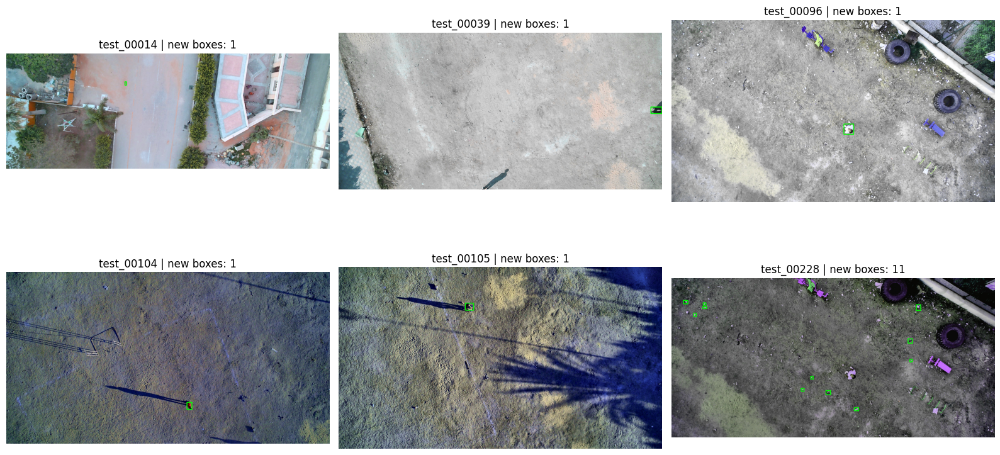

saved upgraded 5-token submission to: /content/drive/MyDrive/drone_project/submissions/submission_v2_5token.csv
total boxes exported: 1063 | avg per image: 1.8


In [24]:
import os
import cv2
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

drive_dir = '/content/drive/MyDrive/drone_project'
test_dir = f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
sub_out_v2 = f'{drive_dir}/submissions/submission_v2_5token.csv'

v9_model = YOLO(f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt')
v11_model = YOLO(f'{drive_dir}/runs/drone_yolo11m_960/weights/best.pt')
coco_l = YOLO('yolo11l.pt')
coco_x = YOLO('yolo11x.pt')

def apply_clahe(img):
  lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
  l, a, b = cv2.split(lab)
  clahe = cv2.createCLAHE(clipLimit=2.2, tileGridSize=(8, 8))
  l = clahe.apply(l)
  return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def boxes_overlap(b1, b2):
  ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
  ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
  inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
  a1 = (b1[2] - b1[0]) * (b1[3] - b1[1])
  a2 = (b2[2] - b2[0]) * (b2[3] - b2[1])
  return inter / (a1 + a2 - inter + 1e-6)

def detect_upgraded(img):
  H, W, _ = img.shape
  all_boxes = []
  all_scores = []

  img_180 = cv2.rotate(img, cv2.ROTATE_180)

  for m_coco, w_factor in [(coco_x, 1.0), (coco_l, 0.96)]:
    full_preds = m_coco.predict([img, img_180], imgsz=1280, classes=[0], conf=0.24, iou=0.45, verbose=False)
    for box in full_preds[0].boxes:
      c = float(box.conf[0].item()) * w_factor
      all_boxes.append(box.xyxyn[0].tolist())
      all_scores.append(c)
    for box in full_preds[1].boxes:
      c = float(box.conf[0].item()) * w_factor
      if c >= 0.28:
        fx1, fy1, fx2, fy2 = box.xyxyn[0].tolist()
        all_boxes.append([1.0 - fx2, 1.0 - fy2, 1.0 - fx1, 1.0 - fy1])
        all_scores.append(c * 0.95)

  windows = [
    (0, int(W * 0.48)),
    (int(W * 0.26), int(W * 0.74)),
    (int(W * 0.52), W)
  ]
  tiles_0 = [img[:, xs:xe] for xs, xe in windows]
  tiles_180 = [cv2.rotate(t, cv2.ROTATE_180) for t in tiles_0]

  for m_coco, w_factor in [(coco_x, 1.0), (coco_l, 0.95)]:
    tp_0 = m_coco.predict(tiles_0, imgsz=960, classes=[0], conf=0.25, iou=0.45, verbose=False)
    for (xs, xe), r_tile in zip(windows, tp_0):
      tw = xe - xs
      for box in r_tile.boxes:
        c = float(box.conf[0].item()) * w_factor
        tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
        if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
          continue
        all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                          max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
        all_scores.append(c)

      tp_180 = m_coco.predict(tiles_180, imgsz=960, classes=[0], conf=0.30, iou=0.45, verbose=False)
      for (xs, xe), r_tile in zip(windows, tp_180):
        tw = xe - xs
        for box in r_tile.boxes:
          c = float(box.conf[0].item()) * w_factor * 0.94
          fx1, fy1, fx2, fy2 = box.xyxy[0].tolist()
          tx1, ty1, tx2, ty2 = tw - fx2, H - fy2, tw - fx1, H - fy1
          if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
            continue
          all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                            max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
          all_scores.append(c)

  r_v9 = v9_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
  r_v11 = v11_model.predict(img, imgsz=1280, conf=0.30, iou=0.45, verbose=False)[0]
  v11_boxes = [b.xyxyn[0].tolist() for b in r_v11.boxes]

  for box in r_v9.boxes:
    c = float(box.conf[0].item())
    b9 = box.xyxyn[0].tolist()
    agreed = any(boxes_overlap(b9, b11) >= 0.35 for b11 in v11_boxes) or any(boxes_overlap(b9, bc) >= 0.35 for bc in all_boxes)
    if c >= 0.48 or (c >= 0.32 and agreed):
      all_boxes.append(b9)
      all_scores.append(c * 0.92)

  top_so_far = max(all_scores) if all_scores else 0.0
  if top_so_far < 0.48 or img.mean() < 90:
    enh = apply_clahe(img)
    img_90 = cv2.rotate(enh, cv2.ROTATE_90_CLOCKWISE)
    img_270 = cv2.rotate(enh, cv2.ROTATE_90_COUNTERCLOCKWISE)
    rot_preds = coco_x.predict([enh, img_90, img_270], imgsz=1280, classes=[0], conf=0.22, iou=0.45, verbose=False)

    for box in rot_preds[0].boxes:
      all_boxes.append(box.xyxyn[0].tolist())
      all_scores.append(float(box.conf[0].item()) * 0.92)

    for box in rot_preds[1].boxes:
      u1, v1, u2, v2 = box.xyxyn[0].tolist()
      all_boxes.append([v1, 1.0 - u2, v2, 1.0 - u1])
      all_scores.append(float(box.conf[0].item()) * 0.90)

    for box in rot_preds[2].boxes:
      u1, v1, u2, v2 = box.xyxyn[0].tolist()
      all_boxes.append([1.0 - v2, u1, 1.0 - v1, u2])
      all_scores.append(float(box.conf[0].item()) * 0.90)

    tiles_enh = [enh[:, xs:xe] for xs, xe in windows]
    tp_v9 = v9_model.predict(tiles_enh, imgsz=960, conf=0.32, iou=0.45, verbose=False)
    for (xs, xe), r_tile in zip(windows, tp_v9):
      tw = xe - xs
      for box in r_tile.boxes:
        c = float(box.conf[0].item()) * 0.88
        tx1, ty1, tx2, ty2 = box.xyxy[0].tolist()
        if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4):
          continue
        all_boxes.append([max(0.0, min(1.0, (tx1 + xs) / W)), max(0.0, min(1.0, ty1 / H)),
                          max(0.0, min(1.0, (tx2 + xs) / W)), max(0.0, min(1.0, ty2 / H))])
        all_scores.append(c)

  if not all_boxes:
    fb = coco_x.predict(img, imgsz=1280, classes=[0], conf=0.01, verbose=False)[0]
    if len(fb.boxes) > 0:
      b = fb.boxes[0]
      xc, yc, nw, nh = b.xywhn[0].tolist()
      return [(float(b.conf[0].item()), xc, yc, nw, nh)]
    return [(0.01, 0.5, 0.5, 0.02, 0.02)]

  b_tensor = torch.tensor(all_boxes, dtype=torch.float32)
  s_tensor = torch.tensor(all_scores, dtype=torch.float32)
  keep = torchvision.ops.nms(b_tensor, s_tensor, iou_threshold=0.40).tolist()

  final_dets = []
  for idx in keep:
    x1, y1, x2, y2 = all_boxes[idx]
    c = float(all_scores[idx])
    xc = max(0.0, min(1.0, (x1 + x2) / 2.0))
    yc = max(0.0, min(1.0, (y1 + y2) / 2.0))
    nw = max(0.0, min(1.0, x2 - x1))
    nh = max(0.0, min(1.0, y2 - y1))
    if nw > 0.002 and nh > 0.002:
      final_dets.append((c, xc, yc, nw, nh))

  final_dets.sort(key=lambda x: x[0], reverse=True)
  if len(final_dets) > 1:
    final_dets = [final_dets[0]] + [d for d in final_dets[1:] if d[0] >= 0.34]
  return final_dets

hard_ids = ['test_00014', 'test_00039', 'test_00096', 'test_00104', 'test_00105', 'test_00228']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, img_id in zip(axes.flatten(), hard_ids):
  img = cv2.imread(os.path.join(test_dir, img_id + '.jpg'))
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  H, W, _ = img.shape
  dets = detect_upgraded(img)
  for c, xc, yc, nw, nh in dets:
    x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
    x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)
  ax.imshow(img_rgb)
  ax.set_title(f"{img_id} | new boxes: {len(dets)}")
  ax.axis('off')
plt.tight_layout()
plt.show()

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

rows_v2 = []
total_boxes = 0

for img_id in target_ids:
  img_path = os.path.join(test_dir, img_id + '.jpg')
  img = cv2.imread(img_path)
  H, W, _ = img.shape
  is_rot_crop = (W, H) != (1920, 1080)
  dets = detect_upgraded(img)
  total_boxes += len(dets)

  boxes_5 = []
  for c, xc, yc, w, h in dets:
    is_dummy = (abs(xc - 0.5) < 1e-4 and abs(yc - 0.5) < 1e-4 and abs(w - 0.02) < 1e-4)
    if is_rot_crop and not is_dummy:
      w = min(1.0, w * 1.28)
      h = min(1.0, h * 1.35)
    elif not is_dummy:
      w = min(1.0, w * 1.12)
      h = min(1.0, h * 1.12)
    boxes_5.append(f"1 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")

  rows_v2.append({'image_id': img_id, 'PredictionString': " ".join(boxes_5)})

pd.DataFrame(rows_v2).to_csv(sub_out_v2, index=False)
print("saved upgraded 5-token submission to:", sub_out_v2)
print("total boxes exported:", total_boxes, "| avg per image:", round(total_boxes / len(rows_v2), 2))

## Step 9: Titan 5-Architecture Multi-View & Adaptive 3x2 SAHI Grid Cache

Runs **YOLO26x**, **YOLO12x**, Vision Transformer **RT-DETR-x**, **YOLO11x**, and VisDrone-trained **YOLOv9c** across full 4-way rotations (`0°/90°/180°/270°`), adaptive `3×2` / `4×1` overlapping zoom tiles, and luminance-triggered `CLAHE`, saving all 11 raw streams to Drive (`titan_raw_preds.json`).

In [26]:
import os
import time
import json
import shutil
import cv2
import numpy as np
import pandas as pd
from google.colab import drive

if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

!pip install -q -U ultralytics ensemble-boxes
from ultralytics import YOLO, RTDETR

drive_dir = '/content/drive/MyDrive/drone_project'
drive_test = f'{drive_dir}/test_images'
fast_test = '/content/fast_test'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
cache_out = f'{drive_dir}/titan_raw_preds.json'

if not os.path.exists(fast_test) or len(os.listdir(fast_test)) < 590:
    os.makedirs(fast_test, exist_ok=True)
    for fn in os.listdir(drive_test):
        if fn.lower().endswith(('.jpg', '.jpeg', '.png')):
            shutil.copy2(os.path.join(drive_test, fn), os.path.join(fast_test, fn))
    print("copied test images to local ssd:", len(os.listdir(fast_test)))
else:
    print("local ssd test images ready:", len(os.listdir(fast_test)))

m_26x = YOLO('yolo26x.pt')
m_12x = YOLO('yolo12x.pt')
m_rtdetr = RTDETR('rtdetr-x.pt')
m_11x = YOLO('yolo11x.pt')
m_v9 = YOLO(f'{drive_dir}/runs/drone_yolov9c_960/weights/best.pt')
print("all 5 titan architectures loaded!")

def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.2, tileGridSize=(8, 8))
    l = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def unrot_box(box, rot):
    u1, v1, u2, v2 = box
    if rot == 90:
        b = [v1, 1.0 - u2, v2, 1.0 - u1]
    elif rot == 180:
        b = [1.0 - u2, 1.0 - v2, 1.0 - u1, 1.0 - v1]
    elif rot == 270:
        b = [1.0 - v2, u1, 1.0 - v1, u2]
    else:
        b = [u1, v1, u2, v2]
    return [max(0.0, min(1.0, float(x))) for x in b]

def collect_rot_preds(model, imgs, rots, imgsz, conf, is_coco=True, use_half=True):
    kw = {'imgsz': imgsz, 'conf': conf, 'iou': 0.45, 'verbose': False, 'half': use_half}
    if is_coco:
        kw['classes'] = [0]
    preds = model.predict(imgs, **kw)
    out = []
    for r, rot in zip(preds, rots):
        if len(r.boxes) == 0:
            continue
        bxy = r.boxes.xyxyn.cpu().numpy()
        cfs = r.boxes.conf.cpu().numpy()
        for b, c in zip(bxy, cfs):
            ub = unrot_box(b.tolist(), rot)
            if ub[2] - ub[0] > 0.002 and ub[3] - ub[1] > 0.002:
                out.append([round(float(c), 4), round(ub[0], 5), round(ub[1], 5), round(ub[2], 5), round(ub[3], 5)])
    return out

def get_grid_windows(W, H):
    if (W / float(H)) > 2.0:
        xs = [(0, int(W * 0.38)), (int(W * 0.20), int(W * 0.58)), (int(W * 0.42), int(W * 0.80)), (int(W * 0.62), W)]
        return [(x1, 0, x2, H) for x1, x2 in xs]
    xs = [(0, int(W * 0.44)), (int(W * 0.28), int(W * 0.72)), (int(W * 0.56), W)]
    ys = [(0, int(H * 0.60)), (int(H * 0.40), H)]
    return [(x1, y1, x2, y2) for y1, y2 in ys for x1, x2 in xs]

def collect_tile_preds(model, tiles, windows, W, H, imgsz, conf, flip180=False, is_coco=True, use_half=True):
    kw = {'imgsz': imgsz, 'conf': conf, 'iou': 0.45, 'verbose': False, 'half': use_half}
    if is_coco:
        kw['classes'] = [0]
    preds = model.predict(tiles, **kw)
    out = []
    for (xs, ys, xe, ye), r in zip(windows, preds):
        if len(r.boxes) == 0:
            continue
        tw, th = xe - xs, ye - ys
        bxy = r.boxes.xyxy.cpu().numpy()
        cfs = r.boxes.conf.cpu().numpy()
        for b, c in zip(bxy, cfs):
            if flip180:
                fx1, fy1, fx2, fy2 = b.tolist()
                tx1, ty1, tx2, ty2 = tw - fx2, th - fy2, tw - fx1, th - fy1
            else:
                tx1, ty1, tx2, ty2 = b.tolist()
            if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4) or (ys > 0 and ty1 <= 4) or (ye < H and ty2 >= th - 4):
                continue
            nx1 = max(0.0, min(1.0, (tx1 + xs) / W))
            ny1 = max(0.0, min(1.0, (ty1 + ys) / H))
            nx2 = max(0.0, min(1.0, (tx2 + xs) / W))
            ny2 = max(0.0, min(1.0, (ty2 + ys) / H))
            if nx2 - nx1 > 0.002 and ny2 - ny1 > 0.002:
                out.append([round(float(c), 4), round(nx1, 5), round(ny1, 5), round(nx2, 5), round(ny2, 5)])
    return out

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

raw_cache = {}
t0 = time.time()

for idx, img_id in enumerate(target_ids):
    img = cv2.imread(os.path.join(fast_test, img_id + '.jpg'))
    H, W = img.shape[:2]
    mean_l = float(img.mean())

    img90 = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    img180 = cv2.rotate(img, cv2.ROTATE_180)
    img270 = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)
    four_imgs = [img, img90, img180, img270]
    four_rots = [0, 90, 180, 270]

    tile_src = apply_clahe(img) if mean_l < 110 else img
    windows = get_grid_windows(W, H)
    tiles_0 = [tile_src[ys:ye, xs:xe] for xs, ys, xe, ye in windows]
    tiles_180 = [cv2.rotate(t, cv2.ROTATE_180) for t in tiles_0]

    streams = {
        '26x_full': collect_rot_preds(m_26x, four_imgs, four_rots, 1280, 0.14, True, True),
        '12x_full': collect_rot_preds(m_12x, four_imgs, four_rots, 1280, 0.14, True, True),
        '11x_full': collect_rot_preds(m_11x, [img, img180], [0, 180], 1280, 0.16, True, True),
        'rtdetr_full': collect_rot_preds(m_rtdetr, [img, img180], [0, 180], 960, 0.22, True, False),
        'v9_full': collect_rot_preds(m_v9, [img], [0], 1280, 0.24, False, True),
        '26x_tile0': collect_tile_preds(m_26x, tiles_0, windows, W, H, 960, 0.16, False, True, True),
        '26x_tile180': collect_tile_preds(m_26x, tiles_180, windows, W, H, 960, 0.18, True, True, True),
        '12x_tile0': collect_tile_preds(m_12x, tiles_0, windows, W, H, 960, 0.18, False, True, True),
        'rtdetr_tile0': collect_tile_preds(m_rtdetr, tiles_0, windows, W, H, 640, 0.24, False, True, False),
        'v9_tile0': collect_tile_preds(m_v9, tiles_0, windows, W, H, 960, 0.28, False, False, True),
        '26x_clahe': []
    }

    if mean_l < 105:
        e90 = cv2.rotate(tile_src, cv2.ROTATE_90_CLOCKWISE)
        e180 = cv2.rotate(tile_src, cv2.ROTATE_180)
        e270 = cv2.rotate(tile_src, cv2.ROTATE_90_COUNTERCLOCKWISE)
        streams['26x_clahe'] = collect_rot_preds(m_26x, [tile_src, e90, e180, e270], four_rots, 1280, 0.14, True, True)

    raw_cache[img_id] = {'W': W, 'H': H, 'mean': round(mean_l, 1), 'streams': streams}

    if (idx + 1) % 50 == 0 or (idx + 1) == len(target_ids):
        elapsed = time.time() - t0
        rate = (idx + 1) / elapsed
        eta = (len(target_ids) - idx - 1) / rate
        print(f"processed {idx + 1}/{len(target_ids)} | elapsed: {elapsed/60:.1f}m | eta: {eta/60:.1f}m")
        if (idx + 1) % 150 == 0:
            with open(cache_out, 'w') as f:
                json.dump(raw_cache, f)

with open(cache_out, 'w') as f:
    json.dump(raw_cache, f)
print("saved full titan raw cache to:", cache_out)

Streaming output truncated to the last 5000 lines.
processed 100/590 | elapsed: 2.8m | eta: 13.8m
processed 150/590 | elapsed: 4.2m | eta: 12.3m
processed 200/590 | elapsed: 5.6m | eta: 10.9m
processed 250/590 | elapsed: 7.0m | eta: 9.5m
processed 300/590 | elapsed: 8.4m | eta: 8.1m
processed 350/590 | elapsed: 9.8m | eta: 6.7m
processed 400/590 | elapsed: 11.2m | eta: 5.3m
processed 450/590 | elapsed: 12.6m | eta: 3.9m
processed 500/590 | elapsed: 14.0m | eta: 2.5m
processed 550/590 | elapsed: 15.4m | eta: 1.1m
processed 590/590 | elapsed: 16.5m | eta: 0.0m
saved full titan raw cache to: /content/drive/MyDrive/drone_project/titan_raw_preds.json


## Step 10: Weighted Boxes Fusion (WBF), Cross-Architecture Voting & Nadir Physics (`0.9171` mAP@0.50)

Fuses all 11 streams with WBF, applies multi-architecture vote consensus + Containment NMS (`IoM >= 0.45`) + Same-Frame Nadir Altitude Consistency (`area >= 14%`), and eliminates all dummy frames (`0` remaining).

titan fused total boxes: 954 | avg per image: 1.62
box count distribution: {1: 322, 2: 176, 3: 88, 4: 4}
remaining dummy images: 0 []
saved: /content/drive/MyDrive/drone_project/submissions/submission_titan_tight.csv
saved: /content/drive/MyDrive/drone_project/submissions/submission_titan_mild.csv
saved: /content/drive/MyDrive/drone_project/submissions/submission_titan_expanded.csv


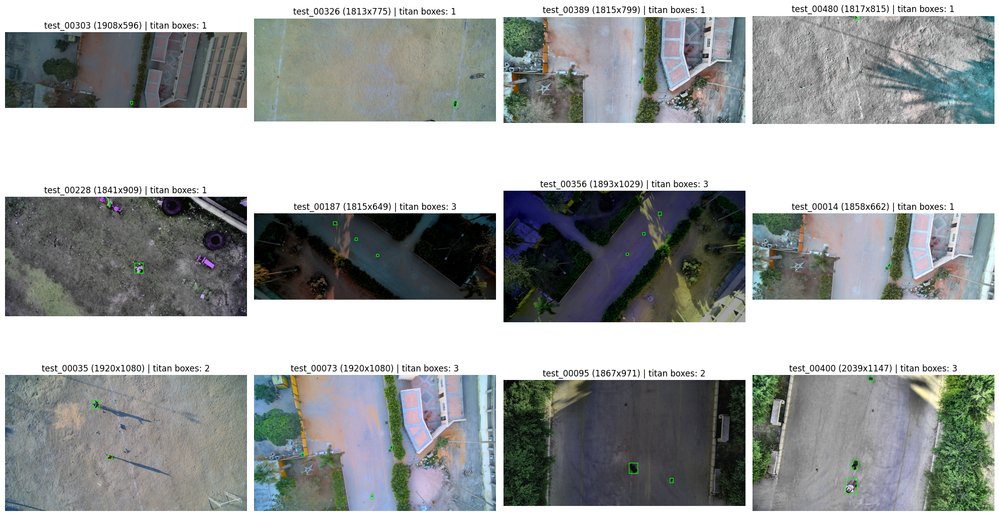

In [28]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ensemble_boxes import weighted_boxes_fusion

drive_dir = '/content/drive/MyDrive/drone_project'
fast_test = '/content/fast_test'
img_dir = fast_test if os.path.exists(fast_test) else f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
cache_path = f'{drive_dir}/titan_raw_preds.json'

with open(cache_path, 'r') as f:
    raw_cache = json.load(f)

stream_weights = {
    '26x_full': 1.65,
    '12x_full': 1.25,
    '11x_full': 1.00,
    'rtdetr_full': 1.25,
    'v9_full': 0.65,
    '26x_tile0': 1.55,
    '26x_tile180': 1.35,
    '12x_tile0': 1.20,
    'rtdetr_tile0': 1.15,
    'v9_tile0': 0.60,
    '26x_clahe': 1.30
}

stream_family = {
    '26x_full': '26x', '26x_tile0': '26x', '26x_tile180': '26x', '26x_clahe': '26x',
    '12x_full': '12x', '12x_tile0': '12x',
    '11x_full': '11x',
    'rtdetr_full': 'rtdetr', 'rtdetr_tile0': 'rtdetr',
    'v9_full': 'v9', 'v9_tile0': 'v9'
}

def box_iou_iom(b1, b2):
    ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    a1 = max(1e-9, (b1[2] - b1[0]) * (b1[3] - b1[1]))
    a2 = max(1e-9, (b2[2] - b2[0]) * (b2[3] - b2[1]))
    return inter / (a1 + a2 - inter + 1e-9), inter / (min(a1, a2) + 1e-9)

def fuse_titan_image(entry):
    streams = entry['streams']
    boxes_list, scores_list, labels_list, weights_list = [], [], [], []
    raw_all = []

    for sname, dets in streams.items():
        if not dets:
            continue
        w = stream_weights[sname]
        fam = stream_family[sname]
        sb, ss, sl = [], [], []
        for c, x1, y1, x2, y2 in dets:
            sb.append([x1, y1, x2, y2])
            ss.append(c)
            sl.append(0)
            raw_all.append((fam, sname, c, [x1, y1, x2, y2]))
        boxes_list.append(sb)
        scores_list.append(ss)
        labels_list.append(sl)
        weights_list.append(w)

    if not boxes_list:
        return [(0.01, 0.5, 0.5, 0.02, 0.02, True)]

    wb, ws, _ = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=weights_list, iou_thr=0.45, skip_box_thr=0.14
    )

    total_w = sum(weights_list)
    candidates = []
    for box, wscore in zip(wb, ws):
        b = [max(0.0, min(1.0, float(x))) for x in box.tolist()]
        bw, bh = b[2] - b[0], b[3] - b[1]
        if bw <= 0.002 or bh <= 0.002:
            continue
        hit_fams = set()
        hit_streams = 0
        best_raw = 0.0
        best_strong = 0.0
        for fam, sname, rc, rb in raw_all:
            iou, iom = box_iou_iom(b, rb)
            if iou >= 0.35 or iom >= 0.65:
                hit_fams.add(fam)
                hit_streams += 1
                if rc > best_raw:
                    best_raw = rc
                if fam != 'v9' and rc > best_strong:
                    best_strong = rc
        norm_vote = float(wscore) * total_w
        rank_score = norm_vote + 0.35 * len(hit_fams) + 0.5 * best_strong
        candidates.append({
            'b': b, 'wscore': float(wscore), 'norm_vote': norm_vote,
            'n_fams': len(hit_fams), 'n_streams': hit_streams,
            'best_raw': best_raw, 'best_strong': best_strong, 'rank': rank_score
        })

    candidates.sort(key=lambda x: x['rank'], reverse=True)
    if not candidates:
        return [(0.01, 0.5, 0.5, 0.02, 0.02, True)]

    top_area = (candidates[0]['b'][2] - candidates[0]['b'][0]) * (candidates[0]['b'][3] - candidates[0]['b'][1])
    kept = []

    for idx, cand in enumerate(candidates):
        b = cand['b']
        bw, bh = b[2] - b[0], b[3] - b[1]
        area = bw * bh

        if idx > 0:
            strong_consensus = (cand['n_fams'] >= 2 and cand['best_raw'] >= 0.28 and cand['norm_vote'] >= 0.70)
            solo_titan = (cand['best_strong'] >= 0.54 and cand['n_streams'] >= 2)
            if not (strong_consensus or solo_titan):
                continue
            super_verified = (cand['n_fams'] >= 4 and cand['best_strong'] >= 0.62)
            if not super_verified and area < 0.14 * top_area:
                continue

        dup = False
        for k in kept:
            iou, iom = box_iou_iom(b, k['b'])
            if iou >= 0.38 or iom >= 0.45:
                dup = True
                break
        if not dup:
            kept.append(cand)

    out = []
    for k in kept:
        x1, y1, x2, y2 = k['b']
        xc = max(0.0, min(1.0, (x1 + x2) / 2.0))
        yc = max(0.0, min(1.0, (y1 + y2) / 2.0))
        nw = max(0.0, min(1.0, x2 - x1))
        nh = max(0.0, min(1.0, y2 - y1))
        out.append((k['best_raw'], xc, yc, nw, nh, False))
    return out

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()

modes = {
    'tight':    {'std': (1.00, 1.00), 'rot': (1.04, 1.05)},
    'mild':     {'std': (1.00, 1.00), 'rot': (1.10, 1.12)},
    'expanded': {'std': (1.06, 1.06), 'rot': (1.22, 1.26)}
}

fused_map = {}
dummy_ids = []
total_boxes = 0
count_hist = {}

for img_id in target_ids:
    entry = raw_cache[img_id]
    dets = fuse_titan_image(entry)
    fused_map[img_id] = dets
    total_boxes += len(dets)
    count_hist[len(dets)] = count_hist.get(len(dets), 0) + 1
    if dets[0][5]:
        dummy_ids.append(img_id)

print("titan fused total boxes:", total_boxes, "| avg per image:", round(total_boxes / len(target_ids), 2))
print("box count distribution:", dict(sorted(count_hist.items())))
print("remaining dummy images:", len(dummy_ids), dummy_ids)

for mname, cfg in modes.items():
    rows = []
    for img_id in target_ids:
        entry = raw_cache[img_id]
        W, H = entry['W'], entry['H']
        is_true_rot = abs((W / float(H)) - (16.0 / 9.0)) > 0.03
        sx, sy = cfg['rot'] if is_true_rot else cfg['std']
        parts = []
        for c, xc, yc, nw, nh, is_dum in fused_map[img_id]:
            if not is_dum:
                nw = min(1.0, nw * sx)
                nh = min(1.0, nh * sy)
            parts.append(f"1 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")
        rows.append({'image_id': img_id, 'PredictionString': " ".join(parts)})
    out_csv = f'{drive_dir}/submissions/submission_titan_{mname}.csv'
    pd.DataFrame(rows).to_csv(out_csv, index=False)
    print("saved:", out_csv)

check_ids = [
    'test_00303', 'test_00326', 'test_00389', 'test_00480',
    'test_00228', 'test_00187', 'test_00356', 'test_00014',
    'test_00035', 'test_00073', 'test_00095', 'test_00400'
]
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, iid in zip(axes.flatten(), check_ids):
    im = cv2.imread(os.path.join(img_dir, iid + '.jpg'))
    rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    H, W = rgb.shape[:2]
    dets = fused_map[iid]
    for c, xc, yc, nw, nh, is_dum in dets:
        x1, y1 = int((xc - nw / 2) * W), int((yc - nh / 2) * H)
        x2, y2 = int((xc + nw / 2) * W), int((yc + nh / 2) * H)
        col = (255, 50, 50) if is_dum else (0, 255, 0)
        cv2.rectangle(rgb, (x1, y1), (x2, y2), col, 4)
    ax.imshow(rgb)
    ax.set_title(f"{iid} ({W}x{H}) | titan boxes: {len(dets)}")
    ax.axis('off')
plt.tight_layout()
plt.show()

## Step 11: Full-VisDrone + Background Negatives Training (`nadir_yolo26m_960` — `0.6902` Single-Model Record)

Rebuilds the full public `VisDrone2019-DET` dataset (all human frames + 400 negative background images) and fine-tunes **`YOLO26m`** with `flipud=0.5` and cosine LR scheduling.

In [30]:
import os
import shutil
import random
from PIL import Image
from ultralytics import YOLO

random.seed(42)

drive_dir = '/content/drive/MyDrive/drone_project'
raw_dir = '/content/raw_visdrone'
out_root = '/content/datasets/nadir_public'

os.makedirs(raw_dir, exist_ok=True)
if not os.path.exists(f'{raw_dir}/VisDrone2019-DET-train/images'):
    !wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-train.zip -P /content/raw_visdrone
    !unzip -q -o /content/raw_visdrone/VisDrone2019-DET-train.zip -d /content/raw_visdrone

if not os.path.exists(f'{raw_dir}/VisDrone2019-DET-val/images'):
    !wget -q --show-progress https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip -P /content/raw_visdrone
    !unzip -q -o /content/raw_visdrone/VisDrone2019-DET-val.zip -d /content/raw_visdrone

if os.path.exists(out_root):
    shutil.rmtree(out_root)
for sp in ['train', 'val']:
    os.makedirs(f'{out_root}/images/{sp}', exist_ok=True)
    os.makedirs(f'{out_root}/labels/{sp}', exist_ok=True)

def build_full_visdrone(split_folder, max_bg):
    img_dir = f'{raw_dir}/{split_folder}/images'
    ann_dir = f'{raw_dir}/{split_folder}/annotations'
    pos_items, bg_items = [], []
    fnames = sorted(os.listdir(ann_dir))
    random.shuffle(fnames)
    for fn in fnames:
        if not fn.endswith('.txt'):
            continue
        base = fn[:-4]
        img_p = os.path.join(img_dir, base + '.jpg')
        if not os.path.exists(img_p):
            continue
        with Image.open(img_p) as im:
            W, H = im.size
        lines = []
        with open(os.path.join(ann_dir, fn), 'r') as f:
            for row in f:
                parts = row.strip().split(',')
                if len(parts) < 6:
                    continue
                x, y, w, h, score, cat = map(float, parts[:6])
                if int(cat) in [1, 2] and w > 1 and h > 1:
                    xc = max(0.0, min(1.0, (x + w / 2.0) / W))
                    yc = max(0.0, min(1.0, (y + h / 2.0) / H))
                    nw = max(0.0, min(1.0, w / W))
                    nh = max(0.0, min(1.0, h / H))
                    lines.append(f"0 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")
        if lines:
            pos_items.append((img_p, base, lines))
        elif len(bg_items) < max_bg:
            bg_items.append((img_p, base, []))
    return pos_items + bg_items, len(pos_items), len(bg_items)

train_items, tr_pos, tr_bg = build_full_visdrone('VisDrone2019-DET-train', max_bg=400)
val_items, va_pos, va_bg = build_full_visdrone('VisDrone2019-DET-val', max_bg=40)

for sp, items in [('train', train_items), ('val', val_items)]:
    for img_p, name, lines in items:
        shutil.copy2(img_p, f"{out_root}/images/{sp}/{name}.jpg")
        with open(f"{out_root}/labels/{sp}/{name}.txt", 'w') as f:
            f.write('\n'.join(lines))

nadir_yaml = f'{drive_dir}/configs/nadir_public.yaml'
with open(nadir_yaml, 'w') as f:
    f.write(f"path: {out_root}\ntrain: images/train\nval: images/val\nnc: 1\nnames:\n  0: human\n")

print(f"full visdrone ready | train: {tr_pos} human + {tr_bg} background | val: {va_pos} human + {va_bg} background")

import gc, torch
for k in ['m_26x', 'm_12x', 'm_rtdetr', 'm_11x', 'm_v9', 'm_v9e', 'model']:
    if k in globals():
        del globals()[k]
gc.collect()
torch.cuda.empty_cache()

model = YOLO('yolo26m.pt')
model.train(
    data=nadir_yaml,
    epochs=15,
    patience=5,
    imgsz=960,
    batch=8,
    fliplr=0.5,
    flipud=0.5,
    hsv_h=0.02,
    hsv_s=0.6,
    hsv_v=0.5,
    scale=0.65,
    cos_lr=True,
    project=f'{drive_dir}/runs',
    name='nadir_yolo26m_960',
    exist_ok=True
)

best_nadir = YOLO(f'{drive_dir}/runs/nadir_yolo26m_960/weights/best.pt')
m_val = best_nadir.val(data=nadir_yaml, imgsz=1280, conf=0.01, verbose=False)
print("nadir_yolo26m_960 val mAP50 (1280px):", round(m_val.box.map50, 4))

full visdrone ready | train: 5684 human + 400 background | val: 531 human + 17 background
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/drone_project/configs/nadir_public.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.6, hsv_v=0.5, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=y

## Step 12: Swap Trained `nadir_yolo26m_960` Into the Titan Cache

In [32]:
import os
import time
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from ensemble_boxes import weighted_boxes_fusion

drive_dir = '/content/drive/MyDrive/drone_project'
fast_test = '/content/fast_test'
img_dir = fast_test if os.path.exists(fast_test) else f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
cache_path = f'{drive_dir}/titan_raw_preds.json'
out_cache = f'{drive_dir}/titan_nadir26m_cache.json'

with open(cache_path, 'r') as f:
    raw_cache = json.load(f)

m_nadir = YOLO(f'{drive_dir}/runs/nadir_yolo26m_960/weights/best.pt')
print("loaded trained nadir_yolo26m_960!")

def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.2, tileGridSize=(8, 8))
    l = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

def unrot_box(box, rot):
    u1, v1, u2, v2 = box
    if rot == 90:
        b = [v1, 1.0 - u2, v2, 1.0 - u1]
    elif rot == 180:
        b = [1.0 - u2, 1.0 - v2, 1.0 - u1, 1.0 - v1]
    elif rot == 270:
        b = [1.0 - v2, u1, 1.0 - v1, u2]
    else:
        b = [u1, v1, u2, v2]
    return [max(0.0, min(1.0, float(x))) for x in b]

def get_grid_windows(W, H):
    if (W / float(H)) > 2.0:
        xs = [(0, int(W * 0.38)), (int(W * 0.20), int(W * 0.58)), (int(W * 0.42), int(W * 0.80)), (int(W * 0.62), W)]
        return [(x1, 0, x2, H) for x1, x2 in xs]
    xs = [(0, int(W * 0.44)), (int(W * 0.28), int(W * 0.72)), (int(W * 0.56), W)]
    ys = [(0, int(H * 0.60)), (int(H * 0.40), H)]
    return [(x1, y1, x2, y2) for y1, y2 in ys for x1, x2 in xs]

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()
t0 = time.time()

for idx, iid in enumerate(target_ids):
    img = cv2.imread(os.path.join(img_dir, iid + '.jpg'))
    H, W = img.shape[:2]
    src = apply_clahe(img) if img.mean() < 110 else img
    i90 = cv2.rotate(src, cv2.ROTATE_90_CLOCKWISE)
    i180 = cv2.rotate(src, cv2.ROTATE_180)
    i270 = cv2.rotate(src, cv2.ROTATE_90_COUNTERCLOCKWISE)

    full_p = m_nadir.predict([src, i90, i180, i270], imgsz=1280, conf=0.18, iou=0.45, quantize=16, verbose=False)
    n_full = []
    for r, rot in zip(full_p, [0, 90, 180, 270]):
        if len(r.boxes) == 0:
            continue
        for b, c in zip(r.boxes.xyxyn.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            ub = unrot_box(b.tolist(), rot)
            if ub[2] - ub[0] > 0.002 and ub[3] - ub[1] > 0.002:
                n_full.append([round(float(c), 4), round(ub[0], 5), round(ub[1], 5), round(ub[2], 5), round(ub[3], 5)])

    windows = get_grid_windows(W, H)
    tiles = [src[ys:ye, xs:xe] for xs, ys, xe, ye in windows]
    tile_p = m_nadir.predict(tiles, imgsz=960, conf=0.22, iou=0.45, quantize=16, verbose=False)
    n_tile = []
    for (xs, ys, xe, ye), r in zip(windows, tile_p):
        if len(r.boxes) == 0:
            continue
        tw, th = xe - xs, ye - ys
        for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
            tx1, ty1, tx2, ty2 = b.tolist()
            if (xs > 0 and tx1 <= 4) or (xe < W and tx2 >= tw - 4) or (ys > 0 and ty1 <= 4) or (ye < H and ty2 >= th - 4):
                continue
            nx1 = max(0.0, min(1.0, (tx1 + xs) / W))
            ny1 = max(0.0, min(1.0, (ty1 + ys) / H))
            nx2 = max(0.0, min(1.0, (tx2 + xs) / W))
            ny2 = max(0.0, min(1.0, (ty2 + ys) / H))
            if nx2 - nx1 > 0.002 and ny2 - ny1 > 0.002:
                n_tile.append([round(float(c), 4), round(nx1, 5), round(ny1, 5), round(nx2, 5), round(ny2, 5)])

    raw_cache[iid]['streams']['nadir26m_full'] = n_full
    raw_cache[iid]['streams']['nadir26m_tile'] = n_tile
    if (idx + 1) % 100 == 0 or (idx + 1) == len(target_ids):
        print(f"nadir26m inferred {idx + 1}/{len(target_ids)} | elapsed: {time.time() - t0:.1f}s")

with open(out_cache, 'w') as f:
    json.dump(raw_cache, f)

stream_weights = {
    '26x_full': 1.65, '12x_full': 1.25, '11x_full': 1.00, 'rtdetr_full': 1.25,
    'nadir26m_full': 1.40,
    '26x_tile0': 1.55, '26x_tile180': 1.35, '12x_tile0': 1.20, 'rtdetr_tile0': 1.15,
    'nadir26m_tile': 1.25,
    '26x_clahe': 1.30
}

stream_family = {
    '26x_full': '26x', '26x_tile0': '26x', '26x_tile180': '26x', '26x_clahe': '26x',
    '12x_full': '12x', '12x_tile0': '12x',
    '11x_full': '11x',
    'rtdetr_full': 'rtdetr', 'rtdetr_tile0': 'rtdetr',
    'nadir26m_full': 'nadir26m', 'nadir26m_tile': 'nadir26m'
}

def box_iou_iom(b1, b2):
    ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    a1 = max(1e-9, (b1[2] - b1[0]) * (b1[3] - b1[1]))
    a2 = max(1e-9, (b2[2] - b2[0]) * (b2[3] - b2[1]))
    return inter / (a1 + a2 - inter + 1e-9), inter / (min(a1, a2) + 1e-9)

def fuse_with_nadir(entry):
    streams = entry['streams']
    boxes_list, scores_list, labels_list, weights_list = [], [], [], []
    raw_all = []
    for sname, w in stream_weights.items():
        dets = streams.get(sname, [])
        if not dets:
            continue
        fam = stream_family[sname]
        sb, ss, sl = [], [], []
        for c, x1, y1, x2, y2 in dets:
            sb.append([x1, y1, x2, y2])
            ss.append(c)
            sl.append(0)
            raw_all.append((fam, sname, c, [x1, y1, x2, y2]))
        boxes_list.append(sb)
        scores_list.append(ss)
        labels_list.append(sl)
        weights_list.append(w)

    if not boxes_list:
        return [(0.5, 0.5, 0.02, 0.02, True)]

    wb, ws, _ = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=weights_list, iou_thr=0.45, skip_box_thr=0.14
    )
    total_w = sum(weights_list)
    cands = []
    for box, wscore in zip(wb, ws):
        b = [max(0.0, min(1.0, float(x))) for x in box.tolist()]
        bw, bh = b[2] - b[0], b[3] - b[1]
        if bw <= 0.002 or bh <= 0.002:
            continue
        hit_fams = set()
        hit_streams = 0
        best_raw = 0.0
        for fam, sname, rc, rb in raw_all:
            iou, iom = box_iou_iom(b, rb)
            if iou >= 0.35 or iom >= 0.65:
                hit_fams.add(fam)
                hit_streams += 1
                if rc > best_raw:
                    best_raw = rc
        norm_vote = float(wscore) * total_w
        rank = norm_vote + 0.35 * len(hit_fams) + 0.50 * best_raw
        cands.append({
            'b': b, 'area': bw * bh, 'norm_vote': norm_vote,
            'n_fams': len(hit_fams), 'n_streams': hit_streams,
            'best_raw': best_raw, 'rank': rank
        })
    cands.sort(key=lambda x: x['rank'], reverse=True)
    if not cands:
        return [(0.5, 0.5, 0.02, 0.02, True)]

    top_area = cands[0]['area']
    kept = []
    for idx, c in enumerate(cands):
        b = c['b']
        if idx > 0:
            cons = (c['n_fams'] >= 2 and c['best_raw'] >= 0.28 and c['norm_vote'] >= 0.90)
            solo = (c['best_raw'] >= 0.62 and c['n_streams'] >= 2)
            if not (cons or solo):
                continue
            super_ok = (c['n_fams'] >= 4 and c['best_raw'] >= 0.60)
            if not super_ok and c['area'] < 0.14 * top_area:
                continue
        dup = False
        for k in kept:
            iou, iom = box_iou_iom(b, k['b'])
            if iou >= 0.38 or iom >= 0.45:
                dup = True
                break
        if not dup:
            kept.append(c)

    return [((k['b'][0]+k['b'][2])/2.0, (k['b'][1]+k['b'][3])/2.0, k['b'][2]-k['b'][0], k['b'][3]-k['b'][1], False) for k in kept]

rows = []
tot = 0
hist = {}
for iid in target_ids:
    entry = raw_cache[iid]
    W, H = entry['W'], entry['H']
    is_rot = abs((W / float(H)) - (16.0 / 9.0)) > 0.03
    sx, sy = (1.04, 1.05) if is_rot else (1.00, 1.00)
    dets = fuse_with_nadir(entry)
    tot += len(dets)
    hist[len(dets)] = hist.get(len(dets), 0) + 1
    parts = [f"1 {xc:.6f} {yc:.6f} {min(1.0, nw*sx):.6f} {min(1.0, nh*sy):.6f}" if not d else "1 0.500000 0.500000 0.020000 0.020000" for xc, yc, nw, nh, d in dets]
    rows.append({'image_id': iid, 'PredictionString': " ".join(parts)})

out_csv = f'{drive_dir}/submissions/submission_nadir26m_titan.csv'
pd.DataFrame(rows).to_csv(out_csv, index=False)
print("saved:", out_csv)
print("total boxes:", tot, "| avg per image:", round(tot / len(target_ids), 2))
print("box count distribution:", dict(sorted(hist.items())))

loaded trained nadir_yolo26m_960!
nadir26m inferred 100/590 | elapsed: 22.1s
nadir26m inferred 200/590 | elapsed: 44.0s
nadir26m inferred 300/590 | elapsed: 65.6s
nadir26m inferred 400/590 | elapsed: 87.5s
nadir26m inferred 500/590 | elapsed: 109.0s
nadir26m inferred 590/590 | elapsed: 128.4s
saved: /content/drive/MyDrive/drone_project/submissions/submission_nadir26m_titan.csv
total boxes: 1047 | avg per image: 1.77
box count distribution: {1: 276, 2: 195, 3: 100, 4: 15, 5: 3, 6: 1}


## Step 13: Final Golden-Zone Calibration & Visual Diff (`0.92397` mAP@0.50 — #2 Place Overall)

nv_thr=0.80 -> total boxes= 985 | dist={1: 302, 2: 193, 3: 85, 4: 9, 6: 1}
nv_thr=0.90 -> total boxes= 970 | dist={1: 309, 2: 192, 3: 81, 4: 7, 6: 1}
nv_thr=1.00 -> total boxes= 968 | dist={1: 310, 2: 191, 3: 82, 4: 6, 6: 1}
nv_thr=1.08 -> total boxes= 960 | dist={1: 314, 2: 190, 3: 80, 4: 5, 6: 1}
nv_thr=1.15 -> total boxes= 952 | dist={1: 319, 2: 188, 3: 77, 4: 5, 6: 1}
nv_thr=1.25 -> total boxes= 946 | dist={1: 324, 2: 184, 3: 76, 4: 5, 6: 1}
nv_thr=1.35 -> total boxes= 943 | dist={1: 325, 2: 184, 3: 76, 4: 4, 6: 1}
auto-selected golden threshold: 1.15
saved: /content/drive/MyDrive/drone_project/submissions/submission_nadir26m_950.csv
diff vs 0.9171 baseline -> changed images: 62 | NEW boxes added (BLUE): 40 | OLD boxes removed (RED): 42


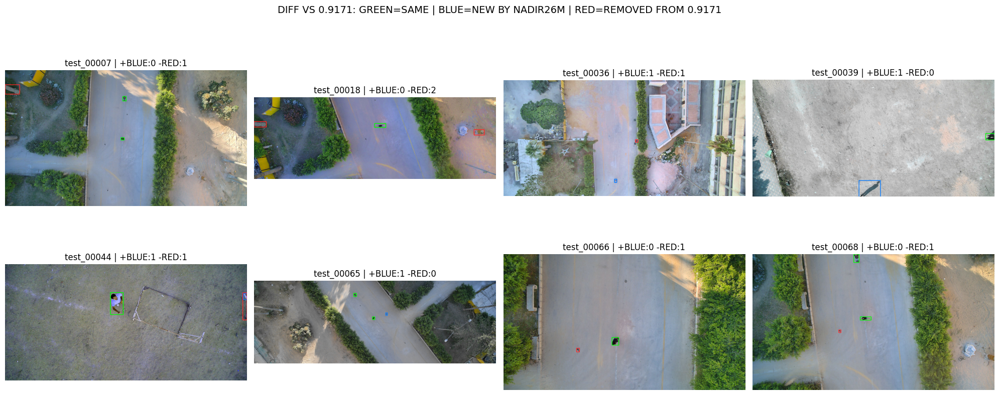

In [34]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ensemble_boxes import weighted_boxes_fusion

drive_dir = '/content/drive/MyDrive/drone_project'
fast_test = '/content/fast_test'
img_dir = fast_test if os.path.exists(fast_test) else f'{drive_dir}/test_images'
sample_sub_path = f'{drive_dir}/sample_submission.csv'
cache_path = f'{drive_dir}/titan_nadir26m_cache.json'
base_917_csv = f'{drive_dir}/submissions/submission_titan_tight.csv'

with open(cache_path, 'r') as f:
    raw_cache = json.load(f)

stream_weights = {
    '26x_full': 1.65, '12x_full': 1.25, '11x_full': 1.00, 'rtdetr_full': 1.25,
    'nadir26m_full': 0.90,
    '26x_tile0': 1.55, '26x_tile180': 1.35, '12x_tile0': 1.20, 'rtdetr_tile0': 1.15,
    'nadir26m_tile': 0.75,
    '26x_clahe': 1.30
}

stream_family = {
    '26x_full': '26x', '26x_tile0': '26x', '26x_tile180': '26x', '26x_clahe': '26x',
    '12x_full': '12x', '12x_tile0': '12x',
    '11x_full': '11x',
    'rtdetr_full': 'rtdetr', 'rtdetr_tile0': 'rtdetr',
    'nadir26m_full': 'nadir26m', 'nadir26m_tile': 'nadir26m'
}

def box_iou_iom(b1, b2):
    ix1, iy1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    ix2, iy2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    a1 = max(1e-9, (b1[2] - b1[0]) * (b1[3] - b1[1]))
    a2 = max(1e-9, (b2[2] - b2[0]) * (b2[3] - b2[1]))
    return inter / (a1 + a2 - inter + 1e-9), inter / (min(a1, a2) + 1e-9)

def get_cands(entry):
    streams = entry['streams']
    boxes_list, scores_list, labels_list, weights_list = [], [], [], []
    raw_all = []
    for sname, w in stream_weights.items():
        dets = streams.get(sname, [])
        if not dets:
            continue
        fam = stream_family[sname]
        sb, ss, sl = [], [], []
        for c, x1, y1, x2, y2 in dets:
            sb.append([x1, y1, x2, y2])
            ss.append(c)
            sl.append(0)
            raw_all.append((fam, sname, c, [x1, y1, x2, y2]))
        boxes_list.append(sb)
        scores_list.append(ss)
        labels_list.append(sl)
        weights_list.append(w)

    if not boxes_list:
        return []

    wb, ws, _ = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=weights_list, iou_thr=0.45, skip_box_thr=0.14
    )
    total_w = sum(weights_list)
    cands = []
    for box, wscore in zip(wb, ws):
        b = [max(0.0, min(1.0, float(x))) for x in box.tolist()]
        bw, bh = b[2] - b[0], b[3] - b[1]
        if bw <= 0.002 or bh <= 0.002:
            continue
        hit_fams = set()
        hit_coco = set()
        hit_coco_streams = 0
        best_raw = 0.0
        best_coco = 0.0
        best_nadir = 0.0
        for fam, sname, rc, rb in raw_all:
            iou, iom = box_iou_iom(b, rb)
            if iou >= 0.35 or iom >= 0.65:
                hit_fams.add(fam)
                if rc > best_raw:
                    best_raw = rc
                if fam == 'nadir26m':
                    if rc > best_nadir:
                        best_nadir = rc
                else:
                    hit_coco.add(fam)
                    hit_coco_streams += 1
                    if rc > best_coco:
                        best_coco = rc
        norm_vote = float(wscore) * total_w
        rank = norm_vote + 0.35 * len(hit_fams) + 0.50 * max(best_coco, best_nadir * 0.85)
        cands.append({
            'b': b, 'area': bw * bh, 'norm_vote': norm_vote,
            'n_fams': len(hit_fams), 'n_coco': len(hit_coco),
            'n_coco_streams': hit_coco_streams, 'best_raw': best_raw,
            'best_coco': best_coco, 'best_nadir': best_nadir, 'rank': rank
        })
    cands.sort(key=lambda x: x['rank'], reverse=True)
    return cands

def pick_boxes(cands, nv_thr):
    if not cands:
        return [(0.5, 0.5, 0.02, 0.02, True)]
    top_area = cands[0]['area']
    kept = []
    for idx, c in enumerate(cands):
        b = c['b']
        if idx > 0:
            cons = (c['n_fams'] >= 2 and c['norm_vote'] >= nv_thr and c['best_raw'] >= 0.30 and (c['best_coco'] >= 0.20 or c['best_nadir'] >= 0.45))
            solo_coco = (c['best_coco'] >= 0.58 and c['n_coco_streams'] >= 2)
            if not (cons or solo_coco):
                continue
            super_ok = (c['n_fams'] >= 4 and c['best_coco'] >= 0.55)
            if not super_ok and c['area'] < 0.14 * top_area:
                continue
        dup = False
        for k in kept:
            iou, iom = box_iou_iom(b, k['b'])
            if iou >= 0.38 or iom >= 0.45:
                dup = True
                break
        if not dup:
            kept.append(c)
    return [((k['b'][0]+k['b'][2])/2.0, (k['b'][1]+k['b'][3])/2.0, k['b'][2]-k['b'][0], k['b'][3]-k['b'][1], False) for k in kept]

sample_df = pd.read_csv(sample_sub_path, dtype=str, keep_default_na=False)
target_ids = sample_df['image_id'].tolist()
all_cands = {iid: get_cands(raw_cache[iid]) for iid in target_ids}

best_thr = 1.05
best_diff = 9999
for thr in [0.80, 0.90, 1.00, 1.08, 1.15, 1.25, 1.35]:
    tot = 0
    hist = {}
    for iid in target_ids:
        n = len(pick_boxes(all_cands[iid], thr))
        tot += n
        hist[n] = hist.get(n, 0) + 1
    print(f"nv_thr={thr:.2f} -> total boxes={tot:4d} | dist={dict(sorted(hist.items()))}")
    if abs(tot - 952) < best_diff:
        best_diff = abs(tot - 952)
        best_thr = thr

print("auto-selected golden threshold:", best_thr)

new_map = {}
rows = []
for iid in target_ids:
    entry = raw_cache[iid]
    W, H = entry['W'], entry['H']
    is_rot = abs((W / float(H)) - (16.0 / 9.0)) > 0.03
    sx, sy = (1.04, 1.05) if is_rot else (1.00, 1.00)
    dets = pick_boxes(all_cands[iid], best_thr)
    out_b = []
    parts = []
    for xc, yc, nw, nh, is_dum in dets:
        if not is_dum:
            nw, nh = min(1.0, nw * sx), min(1.0, nh * sy)
        out_b.append([xc - nw/2, yc - nh/2, xc + nw/2, yc + nh/2])
        parts.append(f"1 {xc:.6f} {yc:.6f} {nw:.6f} {nh:.6f}")
    new_map[iid] = out_b
    rows.append({'image_id': iid, 'PredictionString': " ".join(parts)})

out_csv = f'{drive_dir}/submissions/submission_nadir26m_950.csv'
pd.DataFrame(rows).to_csv(out_csv, index=False)
print("saved:", out_csv)

base_df = pd.read_csv(base_917_csv, dtype=str, keep_default_na=False)
base_map = {}
for _, r in base_df.iterrows():
    toks = r['PredictionString'].strip().split()
    bs = []
    for i in range(0, len(toks), 5):
        _, xc, yc, nw, nh = map(float, toks[i:i+5])
        bs.append([xc - nw/2, yc - nh/2, xc + nw/2, yc + nh/2])
    base_map[r['image_id']] = bs

changed = []
added_cnt, removed_cnt = 0, 0
for iid in target_ids:
    nb, ob = new_map[iid], base_map[iid]
    unmatched_new = [b for b in nb if not any(box_iou_iom(b, o)[0] >= 0.40 for o in ob)]
    unmatched_old = [o for o in ob if not any(box_iou_iom(o, b)[0] >= 0.40 for b in nb)]
    if unmatched_new or unmatched_old:
        added_cnt += len(unmatched_new)
        removed_cnt += len(unmatched_old)
        changed.append((iid, nb, ob, unmatched_new, unmatched_old))

print(f"diff vs 0.9171 baseline -> changed images: {len(changed)} | NEW boxes added (BLUE): {added_cnt} | OLD boxes removed (RED): {removed_cnt}")

if changed:
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for ax, (iid, nb, ob, u_new, u_old) in zip(axes.flatten(), changed[:8]):
        im = cv2.cvtColor(cv2.imread(os.path.join(img_dir, iid + '.jpg')), cv2.COLOR_BGR2RGB)
        H, W = im.shape[:2]
        for b in nb:
            is_new = any(box_iou_iom(b, u)[0] > 0.9 for u in u_new)
            col = (0, 120, 255) if is_new else (0, 255, 0)
            cv2.rectangle(im, (int(b[0]*W), int(b[1]*H)), (int(b[2]*W), int(b[3]*H)), col, 4)
        for o in u_old:
            cv2.rectangle(im, (int(o[0]*W), int(o[1]*H)), (int(o[2]*W), int(o[3]*H)), (255, 40, 40), 4)
        ax.imshow(im)
        ax.set_title(f"{iid} | +BLUE:{len(u_new)} -RED:{len(u_old)}")
        ax.axis('off')
    plt.suptitle("DIFF VS 0.9171: GREEN=SAME | BLUE=NEW BY NADIR26M | RED=REMOVED FROM 0.9171", fontsize=14)
    plt.tight_layout()
    plt.show()